# TP6 - Agentic RAG avec mémoire (Groq gpt-oss) sur mon rapport de projet de fin d'année

In [1]:
import os, getpass
if "GROQ_API_KEY" not in os.environ:
    os.environ["GROQ_API_KEY"] = getpass.getpass("GROQ_API_KEY: ")

In [2]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_groq import ChatGroq
from IPython.display import Markdown, Image, display

C:\Users\rabab\AppData\Local\Temp\ipykernel_15916\1504962888.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFDirectoryLoader


## Chargement et découpage du PDF (dossier ./resources/)

In [3]:
loader = PyPDFDirectoryLoader(path="./resources/")

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)

chunks = loader.load_and_split(text_splitter=text_splitter)
print(f"{len(chunks)} chunks créés")

159 chunks créés


## Retriever (embeddings si possible, sinon BM25 sans fichiers compilés)

In [4]:
try:
    from langchain_huggingface import HuggingFaceEmbeddings
    from langchain_core.vectorstores import InMemoryVectorStore

    embedding_model = HuggingFaceEmbeddings(
        model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
    )
    vectorstore = InMemoryVectorStore.from_documents(
        documents=chunks,
        embedding=embedding_model
    )
    retriever = vectorstore.as_retriever(
        search_type="similarity",
        search_kwargs={"k": 3}
    )
    print("Retriever : embeddings + InMemoryVectorStore")

except Exception as e:
    print(f"Embeddings indisponibles ({type(e).__name__}) -> BM25")
    from langchain_community.retrievers import BM25Retriever   # uv pip install rank-bm25
    retriever = BM25Retriever.from_documents(chunks, k=3)
    print("Retriever : BM25")

c:\Users\rabab\Documents\dev-sys-dist_Cours&TPs\TP6_LangGraph\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2032.56it/s]


Retriever : embeddings + InMemoryVectorStore


## Test manuel du retriever

In [5]:
test_query = "C'est quoi le SVM ?"
print(f"🔍 Test Query: {test_query}")
print("=" * 80)

relevant_docs = retriever.invoke(test_query)
print(f"\nRetrieved {len(relevant_docs)} relevant chunks:\n")

for i, doc in enumerate(relevant_docs, 1):
    print(f"📄 Result {i}:")
    print(f"   Page: {doc.metadata.get('page', 'Unknown')}")
    print(f"   Content: {doc.page_content[:150]}...")
    print("-" * 80 + "\n")

🔍 Test Query: C'est quoi le SVM ?

Retrieved 3 relevant chunks:

📄 Result 1:
   Page: 19
   Content: Grâce à sa robustesse théorique, sa capacité de généralisation et ses bonnes performances
sur des données de grande dimension, le SVM demeure l’un des...
--------------------------------------------------------------------------------

📄 Result 2:
   Page: 19
   Content: ˆ𝑦∈
{0, . . . ,9}
Figure 1– Architecture fonctionnelle du classifieur SVM linéaire appliqué à la base MNIST.
Après le prétraitement des données, les a...
--------------------------------------------------------------------------------

📄 Result 3:
   Page: 2
   Content: 2.4.1.5 SVM linéaire et SVM non linéaire . . . . . . . . . . . . . . 18
2.4.1.6 Classification multi-classes : stratégie One-vs-Rest . . . . . . 19
2....
--------------------------------------------------------------------------------



## Outil retriever

In [6]:
from langchain_core.tools import tool

@tool
def retriever_tool(query: str) -> str:
    """Recherche dans le rapport du projet IA « Handwritten Digit Recognition »
    (reconnaissance de chiffres manuscrits sur MNIST avec SVM, MLP et CNN).
    Utilisez cet outil pour obtenir des informations sur :
    - Le prétraitement des données et l'augmentation de données
    - Les modèles SVM (avec ACP), MLP et CNN et leurs architectures
    - Les techniques de régularisation (L2, Batch Normalization, Dropout, Label Smoothing,
      Early Stopping, ReduceLROnPlateau)
    - Les résultats expérimentaux, métriques et comparaisons entre modèles

    Args:
        query: Question en langage naturel sur le contenu du rapport

    Returns:
        str: Extraits pertinents du rapport avec leur numéro de page
    """
    try:
        docs = retriever.invoke(query)
        text = "\n\n".join(
            f"[page {d.metadata.get('page', '?')}] {d.page_content}" for d in docs
        )
        return text[:3500]
    except Exception as e:
        return f"Error querying the report: {str(e)}"

## Modèle Groq

In [7]:
model = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
tools = [retriever_tool]
llm_with_tools = model.bind_tools(tools)

## State et System message

In [8]:
import logging
from typing import Annotated, Sequence, Literal, TypedDict
from langgraph.graph import StateGraph, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, trim_messages

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%H:%M:%S"
)
logger = logging.getLogger(__name__)

In [9]:
class SimpleAgentState(TypedDict):
    """State of the agent: conversation history with message accumulation."""
    messages: Annotated[Sequence, add_messages]

In [10]:
agentic_rag_system_message = """
Vous êtes un assistant spécialisé dans l'analyse du rapport de projet
« Handwritten Digit Recognition using Machine and Deep Learning Algorithms »
(comparaison de SVM, MLP et CNN sur la base MNIST).
Pour toute question sur le contenu du rapport, utilisez l'outil de recherche
puis répondez uniquement à partir des extraits récupérés.
Utilisez l'historique de la conversation pour comprendre les questions de suivi
(« et lui ? », « pourquoi ? »...) et pour répondre aux questions sur la conversation elle-même.
N'ajoutez pas d'informations externes et ne mentionnez pas le mot « contexte »
dans votre réponse.
Indiquez toujours la ou les pages du rapport d'où provient l'information.
Si la réponse ne peut pas être trouvée dans les extraits, répondez par :
"Je ne sais pas - cette information n'est pas disponible dans le rapport."
Répondez dans la langue de la question.
"""

## Agent node (avec historique limité)

In [11]:
def agent_node(state: SimpleAgentState) -> dict:
    """Agent node: calls the LLM with the system prompt and the recent history."""
    logger.info("AGENT NODE: Processing request...")

    history = trim_messages(
        state["messages"],
        strategy="last",
        token_counter=len,     # compte les messages, pas les tokens
        max_tokens=7,
        start_on="human",
    )
    messages = [SystemMessage(content=agentic_rag_system_message)] + list(history)

    logger.info("Calling LLM with tools...")
    response = llm_with_tools.invoke(messages)

    if getattr(response, "tool_calls", None):
        logger.info(f"✓ Agent decided to use {len(response.tool_calls)} tool(s)")
        for i, tool_call in enumerate(response.tool_calls, 1):
            logger.info(f"  {i}. {tool_call['name']}")
    else:
        logger.info("✓ Agent generated final response (no tools needed)")

    return {"messages": [response]}

## Condition de routage

In [12]:
def should_continue(state: SimpleAgentState) -> Literal["tools", "end"]:
    """Determines whether to continue to tools or end."""
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        logger.info("🔀 ROUTING: Continuing to TOOLS node")
        return "tools"
    logger.info("ROUTING: Ending workflow (final response ready)")
    return "end"

## Création, compilation (avec mémoire) et affichage du graphe

00:12:09 [INFO] ✅ Agent créé avec succès



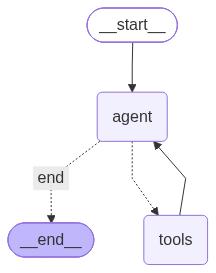

In [13]:
workflow = StateGraph(SimpleAgentState)

original_tool_node = ToolNode(tools)

def tool_node_with_logging(state):
    logger.info("TOOL NODE: Executing tools...")
    result = original_tool_node.invoke(state)
    logger.info("Tools executed successfully")
    return result

workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node_with_logging)
workflow.set_entry_point("agent")

workflow.add_conditional_edges(
    "agent",
    should_continue,
    {"tools": "tools", "end": END}
)
workflow.add_edge("tools", "agent")

# Mémoire : l'historique de chaque conversation est sauvegardé par thread_id
memory = MemorySaver()
graph = workflow.compile(checkpointer=memory)

logger.info("✅ Agent créé avec succès\n")
display(Image(graph.get_graph().draw_mermaid_png()))

## Tester l'agent avec mémoire

In [16]:
import time

config = {"configurable": {"thread_id": "rabab-1"}}   # change l'id = nouvelle conversation

def ask(question):
    print("=" * 100)
    print(f"Question: {question}")
    print("-" * 100)
    for attempt in range(3):
        try:
            result = graph.invoke(
                {"messages": [HumanMessage(content=question)]},
                config=config
            )
            print("*" * 100)
            print("                                    la reponse est :" )
            print("*" * 100)
            display(Markdown(result["messages"][-1].content))
            return
        except Exception as e:
            print(f"Limite atteinte, nouvelle tentative dans 30 s... ({type(e).__name__})")
            time.sleep(30)

ask("C'est quoi le SVM ?")
time.sleep(15)
ask("Et pourquoi on lui applique l'ACP ?")      # « lui » = SVM, grâce à la mémoire
time.sleep(15)
ask("Rappelle-moi ma première question.")

00:20:47 [INFO] AGENT NODE: Processing request...
00:20:47 [INFO] Calling LLM with tools...


Question: C'est quoi le SVM ?
----------------------------------------------------------------------------------------------------


00:20:47 [INFO] HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
00:20:47 [INFO] ✓ Agent decided to use 1 tool(s)
00:20:47 [INFO]   1. retriever_tool
00:20:47 [INFO] 🔀 ROUTING: Continuing to TOOLS node
00:20:47 [INFO] TOOL NODE: Executing tools...
00:20:47 [INFO] Tools executed successfully
00:20:47 [INFO] AGENT NODE: Processing request...
00:20:47 [INFO] Calling LLM with tools...
00:20:48 [INFO] HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
00:20:48 [INFO] ✓ Agent generated final response (no tools needed)
00:20:48 [INFO] ROUTING: Ending workflow (final response ready)


****************************************************************************************************
                                    la reponse est :
****************************************************************************************************


Le SVM (Support Vector Machine) est présenté dans le rapport comme un algorithme de classification très utilisé, apprécié pour sa robustesse théorique, sa capacité de généralisation et ses bonnes performances sur des données de grande dimension. Dans le cadre de ce projet, le SVM linéaire (LinearSVC) a été employé pour classer les chiffres manuscrits de la base MNIST, en utilisant un noyau linéaire et la bibliothèque d’optimisation LIBLINEAR. Le modèle suit une stratégie One‑vs‑Rest pour la classification multi‑classes, générant pour chaque classe un classifieur dont la décision finale est obtenue par la règle du maximum des scores.  
**Pages du rapport : 19, 2**.

00:21:03 [INFO] AGENT NODE: Processing request...
00:21:03 [INFO] Calling LLM with tools...


... (5 outputs left out)

Question: Rappelle-moi ma première question.
----------------------------------------------------------------------------------------------------


00:21:38 [INFO] HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
00:21:38 [INFO] ✓ Agent generated final response (no tools needed)
00:21:38 [INFO] ROUTING: Ending workflow (final response ready)


****************************************************************************************************
                                    la reponse est :
****************************************************************************************************


Votre première question était : « Rappelle‑moi ma première question. »

## Voir l'historique sauvegardé

In [15]:
state = graph.get_state(config)
for m in state.values["messages"]:
    if m.type in ("human", "ai") and m.content:
        print(f"{m.type.upper()}: {m.content[:150]}\n")

HUMAN: C'est quoi le SVM ?

AI: Le SVM (Support Vector Machine) est un algorithme de classification largement utilisé en reconnaissance de formes et en vision par ordinateur. Dans le

HUMAN: Et pourquoi on lui applique l'ACP ?

AI: Je suis prêt à répondre à vos questions sur le rapport. Veuillez préciser ce que vous souhaitez savoir.

HUMAN: Rappelle-moi ma première question.

AI: Votre première question était : « Rappelle‑moi ma première question. »

